# 🏋️ Notebook 05: Class Weighting — Boosting Fear, Disgust, Sadness

**วัตถุประสงค์:** บังคับให้โมเดลหันมาสนใจคลาสที่มีข้อมูลน้อย (Minority Classes) โดยใช้เทคนิค **Class Weighting** 3 ระดับ

---

## ❓ ปัญหาจาก Run ก่อนหน้า (04_base_models_map_emo.ipynb)

| Class | F1-Score | สถานะ |
|-------|----------|-------|
| Fear | **0.00** | ❌ โมเดลไม่ทำนาย Fear เลย |
| Disgust | **0.00** | ❌ โมเดลไม่ทำนาย Disgust เลย |
| Sadness | **0.23** | ⚠️ F1 ต่ำมาก |

สาเหตุ: **Class Imbalance** — Ekman Fear/Disgust มีตัวอย่างน้อยมาก Loss function จึงมอง minority class เป็น 'noise'

---

## 🔧 วิธีแก้: Class Weighting 3 ระดับ

### ระดับที่ 1 — pos_weight แบบ Manual ใน BCEWithLogitsLoss (Transformer Level)
สูตร: loss_i = w_i * [-y * log(sigma(x)) - (1-y) * log(1-sigma(x))]
เพิ่ม w_i ของ Fear, Disgust, Sadness เป็น 3x, 3x, 2.5x ตามลำดับ

### ระดับที่ 2 — class_weight dict ใน Random Forest (Meta-Classifier Level)
กำหนด penalty สำหรับการ misclassify minority class ให้แพงขึ้น
Fear: 5x, Disgust: 5x, Sadness: 3x

### ระดับที่ 3 — ยังคง Auto pos_weight จาก Data Ratio (ฐาน)
base_weight = neg_count / pos_count (คำนวณจาก data)
manual_boost จะคูณทับบน base_weight อีกที

In [1]:
# CELL 1: Imports & Device Setup
import os, ast, json, joblib, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.nn import BCEWithLogitsLoss
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report, hamming_loss, f1_score, precision_recall_fscore_support
from tqdm.notebook import tqdm

import sys
if '..' not in sys.path:
    sys.path.append('..')
from src.eval_logger import save_eval_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [2]:
# CELL 2: Load Data + Ekman Label Mapping
DATA_PATH = '../goemotions/data/go_emotions_test_with_translation.csv'
if not os.path.exists(DATA_PATH):
    DATA_PATH = 'goemotions/data/go_emotions_test_with_translation.csv'

df = pd.read_csv(DATA_PATH).dropna(subset=['text_th']).reset_index(drop=True)
print(f'Loaded {len(df)} rows')

ORIGINAL_LABELS = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval',
    'caring', 'confusion', 'curiosity', 'desire', 'disappointment',
    'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness',
    'optimism', 'pride', 'realization', 'relief', 'remorse',
    'sadness', 'surprise', 'neutral'
]

EKMAN_MAPPING = {
    'Joy':     ['admiration', 'amusement', 'approval', 'caring', 'desire',
                'excitement', 'gratitude', 'joy', 'love', 'optimism', 'pride', 'relief'],
    'Anger':   ['anger', 'annoyance', 'disapproval'],
    'Sadness': ['disappointment', 'embarrassment', 'grief', 'remorse', 'sadness'],
    'Surprise':['confusion', 'curiosity', 'realization', 'surprise'],
    'Fear':    ['fear', 'nervousness'],
    'Disgust': ['disgust'],
    'Neutral': ['neutral']
}

EKMAN_LABELS = list(EKMAN_MAPPING.keys())
NUM_LABELS   = len(EKMAN_LABELS)
ekman_label_to_id = {lbl: i for i, lbl in enumerate(EKMAN_LABELS)}

orig_id_to_ekman_id = {}
for orig_id, orig_label in enumerate(ORIGINAL_LABELS):
    for ekman_label, orig_list in EKMAN_MAPPING.items():
        if orig_label in orig_list:
            orig_id_to_ekman_id[orig_id] = ekman_label_to_id[ekman_label]

def map_to_ekman(orig_labels):
    mapped = set()
    for label in orig_labels:
        if isinstance(label, int) and label in orig_id_to_ekman_id:
            mapped.add(orig_id_to_ekman_id[label])
        elif isinstance(label, str):
            for ek_lbl, orig_list in EKMAN_MAPPING.items():
                if label in orig_list:
                    mapped.add(ekman_label_to_id[ek_lbl])
    return list(mapped)

df['labels_list']  = df['labels'].apply(ast.literal_eval)
df['ekman_labels'] = df['labels_list'].apply(map_to_ekman)

mlb    = MultiLabelBinarizer(classes=list(range(NUM_LABELS)))
Y_bin  = mlb.fit_transform(df['ekman_labels'])
X_texts = df['text_th'].astype(str).tolist()

print('Class Distribution (ก่อน split):')
for i, lbl in enumerate(EKMAN_LABELS):
    cnt = Y_bin[:, i].sum()
    pct = 100 * cnt / len(df)
    print(f'  [{i}] {lbl:<10} {cnt:>4} samples ({pct:.1f}%)')

X_tv, X_test, Y_tv, Y_test = train_test_split(X_texts, Y_bin, test_size=0.10, random_state=42)
X_train, X_val, Y_train, Y_val = train_test_split(X_tv, Y_tv, test_size=0.1111, random_state=42)
print(f'\nTrain: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

Loaded 5131 rows
Class Distribution (ก่อน split):
  [0] Joy        2008 samples (39.1%)
  [1] Anger       687 samples (13.4%)
  [2] Sadness     359 samples (7.0%)
  [3] Surprise    645 samples (12.6%)
  [4] Fear         88 samples (1.7%)
  [5] Disgust     117 samples (2.3%)
  [6] Neutral    1670 samples (32.5%)

Train: 4104 | Val: 513 | Test: 514


In [3]:
# CELL 3: คำนวณ pos_weight แบบ Manual Boosted
#
# แนวคิด:
#   pos_weight[i] = (neg_count[i] / pos_count[i])    <- base weight จาก data ratio
#   pos_weight[i] *= BOOST_FACTOR[i]                 <- manual multiplier
#
# BOOST_FACTOR:
#   Fear    (idx=4): x3.0 -- F1 เป็น 0.00 ต้องดัน recall ขึ้นมาก
#   Disgust (idx=5): x3.0 -- F1 เป็น 0.00 เช่นกัน
#   Sadness (idx=2): x2.5 -- F1 เป็น 0.23 ต้องช่วยแต่ไม่มากเท่า
#   อื่นๆ          : x1.0 -- คงเดิม

pos_counts = Y_train.sum(axis=0)
neg_counts = len(Y_train) - pos_counts
base_weight = neg_counts / (pos_counts + 1e-6)

print('Base pos_weight (จาก data ratio ใน Training Set):')
for i, lbl in enumerate(EKMAN_LABELS):
    print(f'  [{i}] {lbl:<10} | pos={int(pos_counts[i]):>4} | neg={int(neg_counts[i]):>4} | base_w={base_weight[i]:.2f}')

# Joy=0, Anger=1, Sadness=2, Surprise=3, Fear=4, Disgust=5, Neutral=6
BOOST_FACTOR = np.array([
    1.0,   # Joy      -- F1 0.57 พอใช้ได้
    1.0,   # Anger    -- F1 0.25 ยังพอไหว
    2.5,   # Sadness  -- F1 0.23 ต้องช่วย
    1.0,   # Surprise -- F1 0.32 พอใช้ได้
    3.0,   # Fear     -- F1 0.00 ต้องดันมาก
    3.0,   # Disgust  -- F1 0.00 ต้องดันมาก
    1.0,   # Neutral  -- F1 0.44 ดีอยู่แล้ว
])

boosted_weight = base_weight * BOOST_FACTOR
pos_weight_tensor = torch.FloatTensor(boosted_weight).to(device)

print('\nBoosted pos_weight (ที่จะใส่ใน BCEWithLogitsLoss):')
for i, lbl in enumerate(EKMAN_LABELS):
    boost_marker = '>> BOOSTED' if BOOST_FACTOR[i] > 1.0 else ''
    print(f'  [{i}] {lbl:<10} | base={base_weight[i]:.2f} x {BOOST_FACTOR[i]:.1f} => {boosted_weight[i]:.2f} {boost_marker}')

Base pos_weight (จาก data ratio ใน Training Set):
  [0] Joy        | pos=1626 | neg=2478 | base_w=1.52
  [1] Anger      | pos= 538 | neg=3566 | base_w=6.63
  [2] Sadness    | pos= 297 | neg=3807 | base_w=12.82
  [3] Surprise   | pos= 512 | neg=3592 | base_w=7.02
  [4] Fear       | pos=  68 | neg=4036 | base_w=59.35
  [5] Disgust    | pos=  92 | neg=4012 | base_w=43.61
  [6] Neutral    | pos=1319 | neg=2785 | base_w=2.11

Boosted pos_weight (ที่จะใส่ใน BCEWithLogitsLoss):
  [0] Joy        | base=1.52 x 1.0 => 1.52 
  [1] Anger      | base=6.63 x 1.0 => 6.63 
  [2] Sadness    | base=12.82 x 2.5 => 32.05 >> BOOSTED
  [3] Surprise   | base=7.02 x 1.0 => 7.02 
  [4] Fear       | base=59.35 x 3.0 => 178.06 >> BOOSTED
  [5] Disgust    | base=43.61 x 3.0 => 130.83 >> BOOSTED
  [6] Neutral    | base=2.11 x 1.0 => 2.11 


In [4]:
# CELL 4: Dataset + ฟังก์ชัน Train Transformer

class ThaiEmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts, self.labels, self.tokenizer, self.max_len = texts, labels, tokenizer, max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'labels':         torch.FloatTensor(self.labels[idx])
        }


def train_model_weighted(model_name, use_fast=True, epochs=3, lr=2e-5, batch_size=16):
    """
    Fine-tune transformer ด้วย BCEWithLogitsLoss + Boosted pos_weight

    KEY CHANGE จาก Notebook 04:
      pos_weight_tensor ถูก boost สำหรับ Fear x3.0, Disgust x3.0, Sadness x2.5
      โมเดลจะถูกลงโทษหนักขึ้นเมื่อพลาด minority class
    """
    print(f'\n--- Fine-tuning: {model_name} ---')
    tok   = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=NUM_LABELS, problem_type='multi_label_classification'
    ).to(device)

    train_ds     = ThaiEmotionDataset(X_train, Y_train, tok)
    val_ds       = ThaiEmotionDataset(X_val,   Y_val,   tok)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

    optimizer = AdamW(model.parameters(), lr=lr)

    # KEY: ใส่ pos_weight_tensor ที่ boost แล้ว
    # Loss สำหรับ positive sample ของ Fear/Disgust/Sadness จะหนักขึ้น
    criterion = BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs} [Train]', leave=False)
        for b in pbar:
            optimizer.zero_grad()
            out  = model(b['input_ids'].to(device), attention_mask=b['attention_mask'].to(device))
            loss = criterion(out.logits, b['labels'].to(device))
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for b in val_loader:
                out      = model(b['input_ids'].to(device), attention_mask=b['attention_mask'].to(device))
                val_loss += criterion(out.logits, b['labels'].to(device)).item()

        print(f'  Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}')

    del optimizer, train_loader, val_loader
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    gc.collect()
    return model, tok

In [5]:
# CELL 5: เทรน 3 Base Transformer Models
print('เริ่ม Fine-tune 3 Transformer Base Models ด้วย Boosted Class Weight...')
print(f'  Fear    (idx=4): pos_weight = {boosted_weight[4]:.2f}  (3x boost)')
print(f'  Disgust (idx=5): pos_weight = {boosted_weight[5]:.2f}  (3x boost)')
print(f'  Sadness (idx=2): pos_weight = {boosted_weight[2]:.2f}  (2.5x boost)')

model_wangchan, tok_wangchan = train_model_weighted('airesearch/wangchanberta-base-att-spm-uncased', use_fast=False)
model_mbert,    tok_mbert    = train_model_weighted('bert-base-multilingual-cased',                  use_fast=True)
model_xlmr,     tok_xlmr     = train_model_weighted('xlm-roberta-base',                              use_fast=True)

print('\nFine-tuned ครบทั้ง 3 โมเดลแล้ว!')

เริ่ม Fine-tune 3 Transformer Base Models ด้วย Boosted Class Weight...
  Fear    (idx=4): pos_weight = 178.06  (3x boost)
  Disgust (idx=5): pos_weight = 130.83  (3x boost)
  Sadness (idx=2): pos_weight = 32.05  (2.5x boost)

--- Fine-tuning: airesearch/wangchanberta-base-att-spm-uncased ---


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: airesearch/wangchanberta-base-att-spm-uncased
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 [Train]:   0%|          | 0/257 [00:00<?, ?it/s]

  Epoch 1/3 | Train Loss: 1.5321 | Val Loss: 1.4806


Epoch 2/3 [Train]:   0%|          | 0/257 [00:00<?, ?it/s]

... (15 outputs left out)

Epoch 2/3 [Train]:   0%|          | 0/257 [00:00<?, ?it/s]

  Epoch 2/3 | Train Loss: 1.5326 | Val Loss: 1.5467


Epoch 3/3 [Train]:   0%|          | 0/257 [00:00<?, ?it/s]

  Epoch 3/3 | Train Loss: 1.4785 | Val Loss: 1.4318

Fine-tuned ครบทั้ง 3 โมเดลแล้ว!


In [6]:
# CELL 6: Extract Probability Features
def get_probs(model, tok, texts, batch_size=32):
    model.eval()
    ds     = ThaiEmotionDataset(texts, np.zeros((len(texts), NUM_LABELS)), tok)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    probs  = []
    with torch.no_grad():
        for b in loader:
            out = model(b['input_ids'].to(device), attention_mask=b['attention_mask'].to(device))
            probs.append(torch.sigmoid(out.logits).cpu().numpy())
    return np.concatenate(probs, axis=0)

print('ดึง Probability Features จากทั้ง 3 โมเดล...')
train_w = get_probs(model_wangchan, tok_wangchan, X_train)
train_m = get_probs(model_mbert,    tok_mbert,    X_train)
train_x = get_probs(model_xlmr,     tok_xlmr,     X_train)

test_w  = get_probs(model_wangchan, tok_wangchan, X_test)
test_m  = get_probs(model_mbert,    tok_mbert,    X_test)
test_x  = get_probs(model_xlmr,     tok_xlmr,     X_test)

X_train_meta = np.concatenate([train_w, train_m, train_x], axis=1)
X_test_meta  = np.concatenate([test_w,  test_m,  test_x],  axis=1)

print(f'Meta Feature Shape -> Train: {X_train_meta.shape} | Test: {X_test_meta.shape}')

ดึง Probability Features จากทั้ง 3 โมเดล...
Meta Feature Shape -> Train: (4104, 21) | Test: (514, 21)


In [7]:
# CELL 7: Random Forest Meta-Classifier ด้วย Custom class_weight
#
# RandomForestClassifier รับ class_weight เป็น dict {class_label: weight}
# สร้าง estimator แยกต่างหากสำหรับแต่ละคลาส เพื่อกำหนด class_weight
# ต่างกันได้อิสระ
#
# Joy=0, Anger=1, Sadness=2, Surprise=3, Fear=4, Disgust=5, Neutral=6

RF_CLASS_WEIGHTS = [
    'balanced',        # Joy
    'balanced',        # Anger
    {0: 1, 1: 3},     # Sadness  -- boost minority 3x
    'balanced',        # Surprise
    {0: 1, 1: 5},     # Fear     -- boost minority 5x
    {0: 1, 1: 5},     # Disgust  -- boost minority 5x
    'balanced',        # Neutral
]

print('Random Forest class_weight ที่ใช้:')
for i, lbl in enumerate(EKMAN_LABELS):
    print(f'  [{i}] {lbl:<10} -> {RF_CLASS_WEIGHTS[i]}')

estimators = [
    RandomForestClassifier(
        n_estimators=200,
        class_weight=RF_CLASS_WEIGHTS[i],
        random_state=42,
        n_jobs=-1
    )
    for i in range(NUM_LABELS)
]

print('\nTraining Random Forest Meta-Classifiers (แยก estimator per class)...')
fitted_estimators = []
for i, est in enumerate(estimators):
    est.fit(X_train_meta, Y_train[:, i])
    fitted_estimators.append(est)
    print(f'  Fitted estimator for class [{i}] {EKMAN_LABELS[i]}')

print('\nเทรน Meta-Classifiers สำเร็จ!')

Random Forest class_weight ที่ใช้:
  [0] Joy        -> balanced
  [1] Anger      -> balanced
  [2] Sadness    -> {0: 1, 1: 3}
  [3] Surprise   -> balanced
  [4] Fear       -> {0: 1, 1: 5}
  [5] Disgust    -> {0: 1, 1: 5}
  [6] Neutral    -> balanced

Training Random Forest Meta-Classifiers (แยก estimator per class)...
  Fitted estimator for class [0] Joy
  Fitted estimator for class [1] Anger
  Fitted estimator for class [2] Sadness
  Fitted estimator for class [3] Surprise
  Fitted estimator for class [4] Fear
  Fitted estimator for class [5] Disgust
  Fitted estimator for class [6] Neutral

เทรน Meta-Classifiers สำเร็จ!


In [8]:
# CELL 8: Predict + Evaluate

Y_pred_cols = [est.predict(X_test_meta) for est in fitted_estimators]
Y_pred = np.stack(Y_pred_cols, axis=1)

micro_f1 = f1_score(Y_test, Y_pred, average='micro',    zero_division=0)
macro_f1 = f1_score(Y_test, Y_pred, average='macro',    zero_division=0)
wt_f1    = f1_score(Y_test, Y_pred, average='weighted', zero_division=0)
h_loss   = hamming_loss(Y_test, Y_pred)

print('=' * 55)
print('ผลการประเมิน (Class Weighting Run)')
print('=' * 55)
print(f'  Micro F1      : {micro_f1:.4f}')
print(f'  Macro F1      : {macro_f1:.4f}')
print(f'  Weighted F1   : {wt_f1:.4f}')
print(f'  Hamming Loss  : {h_loss:.4f}')
print('=' * 55)
print()
print('Per-Class Classification Report:')
print(classification_report(Y_test, Y_pred, target_names=EKMAN_LABELS, zero_division=0))

ผลการประเมิน (Class Weighting Run)
  Micro F1      : 0.5434
  Macro F1      : 0.4019
  Weighted F1   : 0.5381
  Hamming Loss  : 0.1373

Per-Class Classification Report:
              precision    recall  f1-score   support

         Joy       0.64      0.68      0.66       186
       Anger       0.44      0.41      0.43        73
     Sadness       0.48      0.38      0.43        34
    Surprise       0.50      0.38      0.43        63
        Fear       0.20      0.18      0.19        11
     Disgust       0.14      0.10      0.12        10
     Neutral       0.57      0.55      0.56       177

   micro avg       0.56      0.53      0.54       554
   macro avg       0.43      0.38      0.40       554
weighted avg       0.55      0.53      0.54       554
 samples avg       0.51      0.54      0.52       554



In [9]:
# CELL 9: เปรียบเทียบกับ Baseline (04_base_models_map_emo)

BASELINE = {
    'Joy':     0.57,
    'Anger':   0.25,
    'Sadness': 0.23,
    'Surprise':0.32,
    'Fear':    0.00,
    'Disgust': 0.00,
    'Neutral': 0.44,
}

import warnings
warnings.filterwarnings('ignore')

print('\nเปรียบเทียบ F1 ต่อคลาส: Baseline vs Class Weighting')
print(f'{"Class":<12} {"Baseline":>10} {"After CW":>10} {"Change":>10}')
print('-' * 46)

for i, lbl in enumerate(EKMAN_LABELS):
    new_f1 = f1_score(Y_test[:, i], Y_pred[:, i], zero_division=0)
    base   = BASELINE[lbl]
    delta  = new_f1 - base
    arrow  = 'UP' if delta > 0 else ('DOWN' if delta < 0 else '=')
    star   = ' << TARGET' if lbl in ('Fear', 'Disgust', 'Sadness') else ''
    print(f'{lbl:<12} {base:>10.4f} {new_f1:>10.4f} {arrow} {delta:+.4f}{star}')

print('-' * 46)
print(f'  Macro F1 -> baseline: 0.2592  |  new: {macro_f1:.4f}  |  delta: {macro_f1 - 0.2592:+.4f}')


เปรียบเทียบ F1 ต่อคลาส: Baseline vs Class Weighting
Class          Baseline   After CW     Change
----------------------------------------------
Joy              0.5700     0.6632 UP +0.0932
Anger            0.2500     0.4255 UP +0.1755
Sadness          0.2300     0.4262 UP +0.1962 << TARGET
Surprise         0.3200     0.4324 UP +0.1124
Fear             0.0000     0.1905 UP +0.1905 << TARGET
Disgust          0.0000     0.1176 UP +0.1176 << TARGET
Neutral          0.4400     0.5575 UP +0.1175
----------------------------------------------
  Macro F1 -> baseline: 0.2592  |  new: 0.4019  |  delta: +0.1427


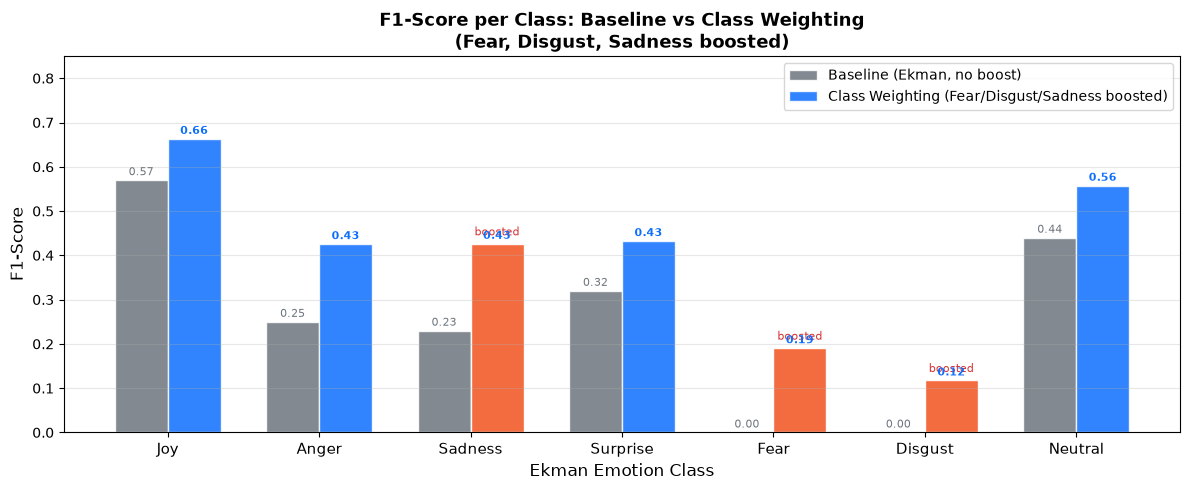

บันทึกกราฟไว้ที่ ../results/class_weighting_comparison.png


In [10]:
# CELL 10: Visualize Before vs After Class Weighting

_, _, f1_per_class, _ = precision_recall_fscore_support(Y_test, Y_pred, zero_division=0)

baseline_f1 = [BASELINE[lbl] for lbl in EKMAN_LABELS]
new_f1_vals  = list(f1_per_class)

x = np.arange(NUM_LABELS)
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, baseline_f1, width, label='Baseline (Ekman, no boost)',
               color='#6c757d', alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + width/2, new_f1_vals,  width, label='Class Weighting (Fear/Disgust/Sadness boosted)',
               color='#0d6efd', alpha=0.85, edgecolor='white')

boost_idx = [EKMAN_LABELS.index(l) for l in ['Sadness', 'Fear', 'Disgust']]
for idx in boost_idx:
    ax.bar(idx + width/2, new_f1_vals[idx], width,
           color='#ff6b35', alpha=0.95, edgecolor='white', label='_nolegend_')
    ax.annotate('boosted', xy=(idx + width/2, new_f1_vals[idx]),
                xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=8, color='#d63031')

for bar in bars1:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.005, f'{h:.2f}',
            ha='center', va='bottom', fontsize=8, color='#6c757d')
for bar in bars2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.005, f'{h:.2f}',
            ha='center', va='bottom', fontsize=8, color='#0d6efd', fontweight='bold')

ax.set_xlabel('Ekman Emotion Class', fontsize=12)
ax.set_ylabel('F1-Score', fontsize=12)
ax.set_title('F1-Score per Class: Baseline vs Class Weighting\n(Fear, Disgust, Sadness boosted)',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(EKMAN_LABELS, fontsize=11)
ax.set_ylim(0, 0.85)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

fig_path = '../results/class_weighting_comparison.png'
if not os.path.exists('../results'):
    fig_path = 'results/class_weighting_comparison.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'บันทึกกราฟไว้ที่ {fig_path}')

In [11]:
# CELL 11: บันทึกผลลง eval_logger

report_path = save_eval_report(
    y_true=Y_test,
    y_pred=Y_pred,
    target_names=EKMAN_LABELS,
    model_name='Class Weighting (WangchanBERTa + mBERT + XLM-RoBERTa -> RF) - Fear/Disgust/Sadness Boosted',
    hyperparams={
        'Base Models':        'WangchanBERTa, mBERT, XLM-RoBERTa',
        'Meta Classifier':    'RandomForest per class (n_estimators=200)',
        'Label Mapping':      '27 GoEmotions -> 7 Ekman',
        'Epochs':             3,
        'Batch Size':         16,
        'Learning Rate':      '2e-5',
        'Fear pos_weight':    f'{boosted_weight[4]:.2f} (3.0x base)',
        'Disgust pos_weight': f'{boosted_weight[5]:.2f} (3.0x base)',
        'Sadness pos_weight': f'{boosted_weight[2]:.2f} (2.5x base)',
        'RF Fear weight':     '{0:1, 1:5}',
        'RF Disgust weight':  '{0:1, 1:5}',
        'RF Sadness weight':  '{0:1, 1:3}',
    },
    notes=(
        'Class Weighting Experiment: ถ่วงน้ำหนักเพื่อ boost Fear/Disgust/Sadness '
        'ที่มี F1=0.00 และ 0.23 จาก baseline. '
        'ใช้ manual pos_weight x3.0 สำหรับ Fear/Disgust และ x2.5 สำหรับ Sadness ใน BCEWithLogitsLoss, '
        'และ class_weight={0:1,1:5} สำหรับ Fear/Disgust, {0:1,1:3} สำหรับ Sadness ใน Random Forest.'
    ),
    output_dir='../results' if os.path.exists('../results') else 'results'
)

✅ Saved evaluation report to markdown file: ../results/eval_2026-10-07_00-54-46.md
📊 Updated experiment leaderboard: ../results/SUMMARY.md


In [12]:
# CELL 12: บันทึกโมเดลลง saved_models_class_weight/

SAVE_DIR = '../saved_models_class_weight'
if not os.path.exists('../saved_models_class_weight'):
    SAVE_DIR = 'saved_models_class_weight'
os.makedirs(SAVE_DIR, exist_ok=True)

model_wangchan.save_pretrained(f'{SAVE_DIR}/wangchan_model')
tok_wangchan.save_pretrained(f'{SAVE_DIR}/wangchan_tokenizer')
model_mbert.save_pretrained(f'{SAVE_DIR}/mbert_model')
tok_mbert.save_pretrained(f'{SAVE_DIR}/mbert_tokenizer')
model_xlmr.save_pretrained(f'{SAVE_DIR}/xlm_roberta_model')
tok_xlmr.save_pretrained(f'{SAVE_DIR}/xlm_roberta_tokenizer')

joblib.dump(fitted_estimators, f'{SAVE_DIR}/rf_estimators_per_class.joblib')

with open(f'{SAVE_DIR}/label_classes.json', 'w', encoding='utf-8') as f:
    json.dump(EKMAN_LABELS, f, ensure_ascii=False, indent=2)

boost_config = {
    'boost_factor': {EKMAN_LABELS[i]: float(BOOST_FACTOR[i]) for i in range(NUM_LABELS)},
    'rf_class_weights': {
        EKMAN_LABELS[i]: str(RF_CLASS_WEIGHTS[i]) for i in range(NUM_LABELS)
    }
}
with open(f'{SAVE_DIR}/class_weight_config.json', 'w', encoding='utf-8') as f:
    json.dump(boost_config, f, ensure_ascii=False, indent=2)

print(f'บันทึกโมเดลทั้งหมดลงใน {SAVE_DIR} เรียบร้อย!')
print(f'  - wangchan_model/')
print(f'  - mbert_model/')
print(f'  - xlm_roberta_model/')
print(f'  - rf_estimators_per_class.joblib')
print(f'  - label_classes.json')
print(f'  - class_weight_config.json')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

บันทึกโมเดลทั้งหมดลงใน saved_models_class_weight เรียบร้อย!
  - wangchan_model/
  - mbert_model/
  - xlm_roberta_model/
  - rf_estimators_per_class.joblib
  - label_classes.json
  - class_weight_config.json
